In [5]:
from google.colab import drive
drive.mount('/content/drive')
!unzip -o /content/drive/MyDrive/sign_data.zip -d /content/
!find /content/data -name "*.npy" | wc -l

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Archive:  /content/drive/MyDrive/sign_data.zip
   creating: /content/data/No/32/
  inflating: /content/data/No/32/20.npy  
  inflating: /content/data/No/32/21.npy  
  inflating: /content/data/No/32/23.npy  
  inflating: /content/data/No/32/22.npy  
  inflating: /content/data/No/32/26.npy  
  inflating: /content/data/No/32/27.npy  
  inflating: /content/data/No/32/25.npy  
  inflating: /content/data/No/32/19.npy  
  inflating: /content/data/No/32/18.npy  
  inflating: /content/data/No/32/24.npy  
  inflating: /content/data/No/32/5.npy  
  inflating: /content/data/No/32/4.npy  
  inflating: /content/data/No/32/6.npy  
  inflating: /content/data/No/32/7.npy  
  inflating: /content/data/No/32/3.npy  
  inflating: /content/data/No/32/2.npy  
  inflating: /content/data/No/32/0.npy  
  inflating: /content/data/No/32/1.npy  
  inflating: /content/data/No/32/9.npy  
 

In [6]:
import numpy as np, os
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

ACTIONS = np.array(['Hello', 'Yes', 'No'])
label_map = {label:num for num, label in enumerate(ACTIONS)}
sequences, labels = [], []
for action in ACTIONS:
    for seq in range(50):  # 50 kar diya
        window = []
        for frame_num in range(30):
            res = np.load(os.path.join('/content/data', action, str(seq), f"{frame_num}.npy"))
            window.append(res)
        sequences.append(window)
        labels.append(label_map[action])

X = np.array(sequences)
y = to_categorical(labels).astype(int)
print("X shape:", X.shape) # (150, 30, 1662) aana chahiye

# Stratified - har sign ka barabar test me jayega
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = Sequential()
model.add(LSTM(64, return_sequences=True, activation='relu', input_shape=(30, 1662)))
model.add(Dropout(0.2))
model.add(LSTM(128, return_sequences=True, activation='relu'))
model.add(Dropout(0.2))
model.add(LSTM(64, return_sequences=False, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(ACTIONS.shape[0], activation='softmax'))

model.compile(optimizer='Adam', loss='categorical_crossentropy', metrics=['categorical_accuracy'])
model.summary()

checkpoint = ModelCheckpoint('/content/best_sign_lstm.h5', monitor='val_categorical_accuracy', save_best_only=True, mode='max', verbose=1)
early = EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)

history = model.fit(X_train, y_train, epochs=100, batch_size=16, validation_data=(X_test, y_test), callbacks=[checkpoint, early])

X shape: (150, 30, 1662)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_3 (LSTM)                   │ (None, 30, 64)         │       442,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_4 (LSTM)                   │ (None, 30, 128)        │        98,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 30, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_5 (LSTM)                   │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 594,691 (2.27 MB)

 Trainable params: 594,691 (2.27 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 605ms/step - categorical_accuracy: 0.2532 - loss: 1.3837
Epoch 1: val_categorical_accuracy improved from None to 0.33333, saving model to /content/best_sign_lstm.h5



Epoch 1: finished saving model to /content/best_sign_lstm.h5
8/8 ━━━━━━━━━━━━━━━━━━━━ 17s 985ms/step - categorical_accuracy: 0.2917 - loss: 1.4691 - val_categorical_accuracy: 0.3333 - val_loss: 1.0935
Epoch 2/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - categorical_accuracy: 0.2888 - loss: 1.1853
Epoch 2: val_categorical_accuracy improved from 0.33333 to 0.50000, saving model to /content/best_sign_lstm.h5



Epoch 2: finished saving model to /content/best_sign_lstm.h5
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - categorical_accuracy: 0.3250 - loss: 1.1454 - val_categorical_accuracy: 0.5000 - val_loss: 1.0356
Epoch 3/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - categorical_accuracy: 0.4277 - loss: 1.0359
Epoch 3: val_categorical_accuracy did not improve from 0.50000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - categorical_accuracy: 0.4417 - loss: 1.0431 - val_categorical_accuracy: 0.5000 - val_loss: 0.9729
Epoch 4/100
7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - categorical_accuracy: 0.4705 - loss: 1.0656
Epoch 4: val_categorical_accuracy did not improve from 0.50000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - categorical_accuracy: 0.4500 - loss: 1.0510 - val_categorical_accuracy: 0.3667 - val_loss: 1.0366
Epoch 5/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - categorical_accuracy: 0.3858 - loss: 1.2066
Epoch 5: val_categorical_accuracy did not improve from 0.50000
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - categor


Epoch 6: finished saving model to /content/best_sign_lstm.h5
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - categorical_accuracy: 0.4750 - loss: 1.0428 - val_categorical_accuracy: 0.5333 - val_loss: 0.9184
Epoch 7/100
7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - categorical_accuracy: 0.3808 - loss: 1.0374
Epoch 7: val_categorical_accuracy did not improve from 0.53333
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - categorical_accuracy: 0.4083 - loss: 1.0473 - val_categorical_accuracy: 0.3333 - val_loss: 1.0778
Epoch 8/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - categorical_accuracy: 0.3461 - loss: 1.0677
Epoch 8: val_categorical_accuracy did not improve from 0.53333
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - categorical_accuracy: 0.3583 - loss: 1.0585 - val_categorical_accuracy: 0.3333 - val_loss: 1.0660
Epoch 9/100
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - categorical_accuracy: 0.2981 - loss: 1.0802
Epoch 9: val_categorical_accuracy did not improve from 0.53333
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - categor

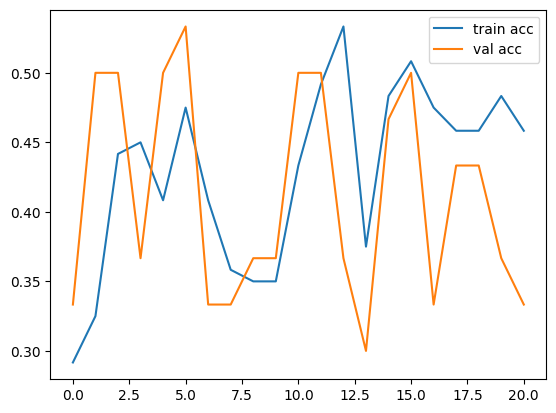

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - categorical_accuracy: 0.5333 - loss: 0.9184
Test Accuracy: 53.33%


In [7]:
import matplotlib.pyplot as plt
plt.plot(history.history['categorical_accuracy'], label='train acc')
plt.plot(history.history['val_categorical_accuracy'], label='val acc')
plt.legend(); plt.show()

loss, acc = model.evaluate(X_test, y_test)
print(f"Test Accuracy: {acc*100:.2f}%")

In [8]:
import numpy as np, os
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import ModelCheckpoint

ACTIONS = np.array(['Hello', 'Yes', 'No'])
label_map = {label:num for num, label in enumerate(ACTIONS)}
sequences, labels = [], []
for action in ACTIONS:
    for seq in range(50):
        window = []
        for frame_num in range(30):
            res = np.load(os.path.join('/content/data', action, str(seq), f"{frame_num}.npy"))
            pose = res[0:132]
            hands = res[1536:1662]
            res_new = np.concatenate([pose, hands])
            window.append(res_new)
        sequences.append(window)
        labels.append(label_map[action])

X = np.array(sequences)
y = to_categorical(labels).astype(int)
print("New X shape:", X.shape)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = Sequential()
model.add(LSTM(64, return_sequences=True, activation='relu', input_shape=(30, 258)))
model.add(LSTM(64, return_sequences=False, activation='relu'))
model.add(Dense(64, activation='relu'))
model.add(Dense(ACTIONS.shape[0], activation='softmax'))

model.compile(optimizer='Adam', loss='categorical_crossentropy', metrics=['categorical_accuracy'])
model.summary()

checkpoint = ModelCheckpoint('/content/best_sign_hands_only.h5', monitor='val_categorical_accuracy', save_best_only=True, mode='max', verbose=1)
history = model.fit(X_train, y_train, epochs=80, batch_size=16, validation_data=(X_test, y_test), callbacks=[checkpoint])

y_pred = model.predict(X_test)
y_true = np.argmax(y_test, axis=1)
y_pred_labels = np.argmax(y_pred, axis=1)
print(confusion_matrix(y_true, y_pred_labels))
print(classification_report(y_true, y_pred_labels, target_names=ACTIONS))

New X shape: (150, 30, 258)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_6 (LSTM)                   │ (None, 30, 64)         │        82,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_7 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 120,067 (469.01 KB)

 Trainable params: 120,067 (469.01 KB)

... (4 outputs left out)


Epoch 6: finished saving model to /content/best_sign_hands_only.h5
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - categorical_accuracy: 0.5833 - loss: 0.9665 - val_categorical_accuracy: 0.6667 - val_loss: 0.9604
Epoch 7/80
6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.5847 - loss: 0.9597
Epoch 7: val_categorical_accuracy did not improve from 0.66667
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - categorical_accuracy: 0.5833 - loss: 0.9234 - val_categorical_accuracy: 0.6000 - val_loss: 0.8831
Epoch 8/80
6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.6158 - loss: 0.8550
Epoch 8: val_categorical_accuracy did not improve from 0.66667
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - categorical_accuracy: 0.7000 - loss: 0.7763 - val_categorical_accuracy: 0.5000 - val_loss: 1.6407
Epoch 9/80
6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.4741 - loss: 1.1319
Epoch 9: val_categorical_accuracy did not improve from 0.66667
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - cate


Epoch 10: finished saving model to /content/best_sign_hands_only.h5
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - categorical_accuracy: 0.6083 - loss: 0.7407 - val_categorical_accuracy: 0.7000 - val_loss: 0.7538
Epoch 11/80
6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.8439 - loss: 0.6710
Epoch 11: val_categorical_accuracy improved from 0.70000 to 0.76667, saving model to /content/best_sign_hands_only.h5



Epoch 11: finished saving model to /content/best_sign_hands_only.h5
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - categorical_accuracy: 0.7750 - loss: 1.0161 - val_categorical_accuracy: 0.7667 - val_loss: 0.6789
Epoch 12/80
6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.6634 - loss: 0.6751
Epoch 12: val_categorical_accuracy did not improve from 0.76667
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - categorical_accuracy: 0.6667 - loss: 0.6894 - val_categorical_accuracy: 0.7000 - val_loss: 0.7140
Epoch 13/80
6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.5714 - loss: 0.7524
Epoch 13: val_categorical_accuracy did not improve from 0.76667
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - categorical_accuracy: 0.7000 - loss: 0.6751 - val_categorical_accuracy: 0.6333 - val_loss: 0.6493
Epoch 14/80
6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.7632 - loss: 0.5369
Epoch 14: val_categorical_accuracy did not improve from 0.76667
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


Epoch 20: finished saving model to /content/best_sign_hands_only.h5
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - categorical_accuracy: 0.6583 - loss: 0.6656 - val_categorical_accuracy: 0.8333 - val_loss: 1.9226
Epoch 21/80
6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.8035 - loss: 0.7049
Epoch 21: val_categorical_accuracy did not improve from 0.83333
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - categorical_accuracy: 0.8333 - loss: 0.6352 - val_categorical_accuracy: 0.8000 - val_loss: 0.8010
Epoch 22/80
6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.8682 - loss: 0.4494
Epoch 22: val_categorical_accuracy did not improve from 0.83333
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - categorical_accuracy: 0.8250 - loss: 0.4983 - val_categorical_accuracy: 0.8000 - val_loss: 1.2969
Epoch 23/80
6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - categorical_accuracy: 0.9283 - loss: 0.2762 
Epoch 23: val_categorical_accuracy did not improve from 0.83333
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/ste